# ESG 633 – Lab 6: Buffer and Overlay Analysis
All layers are reprojected to **EPSG:32643 (UTM 43N)** so buffer distances are in metres.

In [1]:
import os
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, box

# --- change this to wherever the unzipped 'nedumangad' folder lives ---
BASE = "/content/drive/MyDrive/MTech_Shape_files/nedumangad"
if not os.path.exists(BASE):
    BASE = os.environ.get("NEDU_DIR", "nedumangad")   # local fallback

CRS = "EPSG:32643"

## Task 1 – Random points with 100 m, 500 m and 1 km buffers

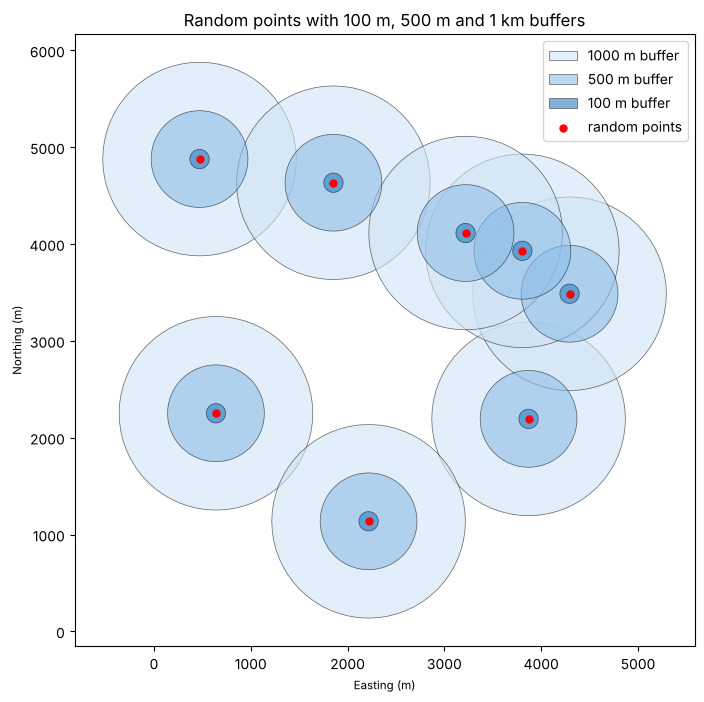

In [2]:
rng = np.random.default_rng(42)
xy = rng.uniform(0, 5000, size=(8, 2))                       # 8 random points in a 5 km x 5 km area
pts = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in xy], crs=CRS)

fig, ax = plt.subplots(figsize=(8, 8))
for dist, col in [(1000, "#cfe3f5"), (500, "#8fbfe8"), (100, "#2f7fc1")]:   # big -> small so all stay visible
    b = pts.copy(); b["geometry"] = pts.buffer(dist)
    b.plot(ax=ax, color=col, edgecolor="k", alpha=0.6, linewidth=0.5, label=f"{dist} m buffer")
pts.plot(ax=ax, color="red", markersize=25, zorder=5, label="random points")
ax.set_title("Random points with 100 m, 500 m and 1 km buffers")
ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)"); ax.set_aspect("equal"); ax.legend(loc="upper right")
plt.show()

## Task 2 – Circle + rectangle, overlay

intersection  area =    41252.1 m2


union         area =   204209.9 m2


difference    area =    84209.9 m2


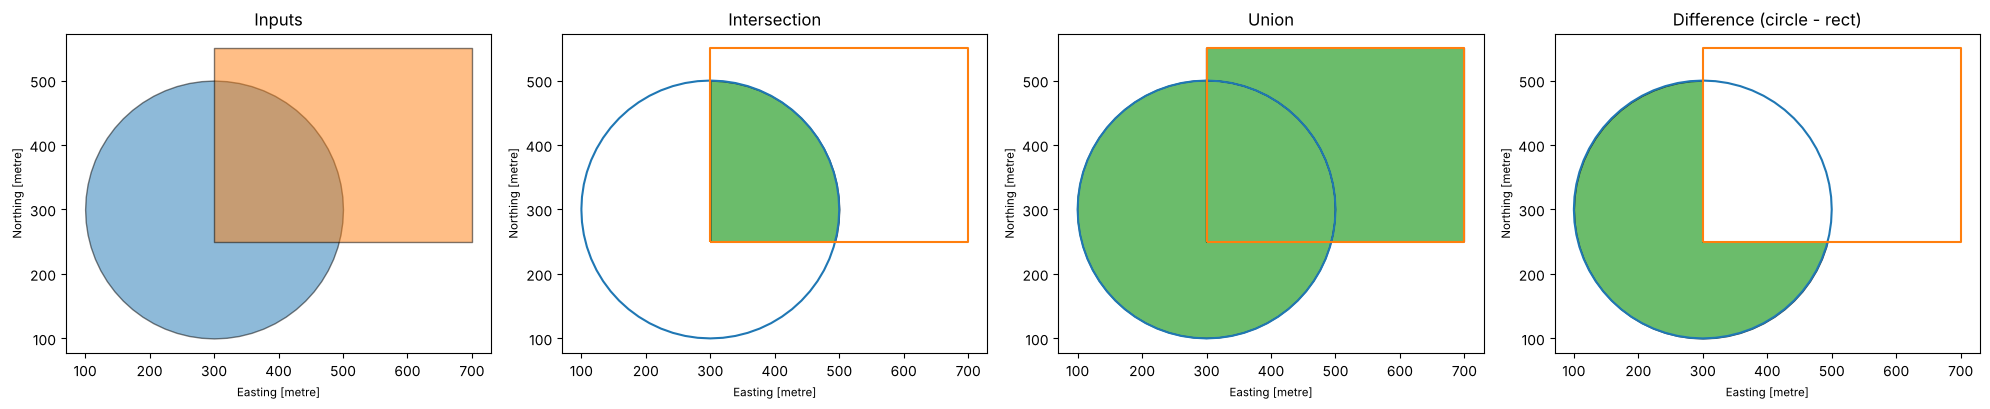

In [3]:
circle = gpd.GeoDataFrame({"shape": ["circle"]}, geometry=[Point(300, 300).buffer(200)], crs=CRS)
rect   = gpd.GeoDataFrame({"shape": ["rectangle"]}, geometry=[box(300, 250, 700, 550)], crs=CRS)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
panels = [("Inputs", None), ("Intersection", "intersection"), ("Union", "union"), ("Difference (circle - rect)", "difference")]
for ax, (title, how) in zip(axes, panels):
    if how is None:
        circle.plot(ax=ax, color="tab:blue", alpha=0.5, edgecolor="k")
        rect.plot(ax=ax, color="tab:orange", alpha=0.5, edgecolor="k")
    else:
        res = gpd.overlay(circle, rect, how=how)
        circle.boundary.plot(ax=ax, color="tab:blue"); rect.boundary.plot(ax=ax, color="tab:orange")
        res.plot(ax=ax, color="tab:green", alpha=0.7, edgecolor="k")
        print(f"{how:13s} area = {res.area.sum():10.1f} m2")
    ax.set_title(title); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

## Load the Nedumangad data
The shapefiles' CRS tags are wrong/missing (coordinates are really lon/lat), so we **overwrite the tag with EPSG:4326, then reproject** – same fix as the starter notebook. Written as a function so re-running the cell is safe.

In [4]:
def load(path):
    g = gpd.read_file(path)
    return g.set_crs("EPSG:4326", allow_override=True).to_crs(CRS)

boundary = load(f"{BASE}/nedumangad_boundary.shp")
b = load(f"{BASE}/buildings/nedumangad_buildings.shp")
r = load(f"{BASE}/roads/nedumangad_road.shp")
w = load(f"{BASE}/waterways/nedumangad_waterways.shp")
p = load(f"{BASE}/pois/nedumangad_pois.shp")
l = load(f"{BASE}/landuse/nedumangad_landuse.shp")
for n, g in dict(boundary=boundary, buildings=b, roads=r, waterways=w, pois=p, landuse=l).items():
    print(f"{n:10s} {len(g):6d} features  {g.crs}")

boundary        1 features  EPSG:32643
buildings   31778 features  EPSG:32643
roads        9912 features  EPSG:32643
waterways    3943 features  EPSG:32643
pois         4291 features  EPSG:32643
landuse       547 features  EPSG:32643


## Task 3 – Explore the data + area of Nedumangad

Area of Nedumangad Taluk: 918.44 km2  (91,844 ha)

Forest polygons in LULC: 53
Forest area: 224.22 km2

LULC classes:
 fclass
farmland             171
residential          107
recreation_ground     86
quarry                67
forest                53
grass                 24
commercial             9
industrial             7
retail                 7
park                   6
nature_reserve         6
orchard                2
scrub                  1
farmyard               1

Primary road names (16): ['Attingal - Nedumangad Road', 'ByPass', 'Irumbupalam New Bridge', 'Kazhakoottam-Kilimanoor Road', 'MC Road', 'MC Road(SH-1)', 'Mannanthala Junction', 'Nedumangad - Mancha Road', 'Nedumangad - Shorlacode Road', 'Nedumangadu - Shorlacode Highway', 'SH2', 'Thiruvananthapuram - Ponmudi Road', 'Thiruvanathapuram - Thenmala Road', 'Thiruvanathapuram - Thenmala Road SH 2', 'Varkala - Parippally - Madathara Road', 'Vembayam - Nedumangad Road']

Road length by class (km):
 fclass
residential     1588.

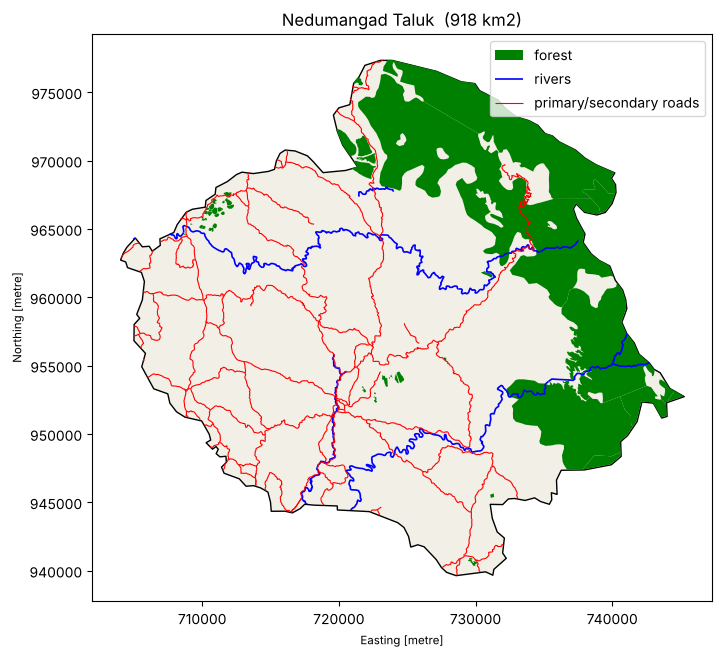

In [5]:
area = boundary.area.sum()
print(f"Area of Nedumangad Taluk: {area/1e6:,.2f} km2  ({area/1e4:,.0f} ha)\n")

print("Forest polygons in LULC:", (l.fclass == "forest").sum())
print("Forest area: %.2f km2" % (l[l.fclass == "forest"].area.sum()/1e6))
print("\nLULC classes:\n", l.fclass.value_counts().to_string())

prim = sorted(r.loc[r.fclass == "primary", "name"].dropna().unique())
print(f"\nPrimary road names ({len(prim)}):", prim)
print("\nRoad length by class (km):\n", (r.assign(L=r.length).groupby("fclass").L.sum()/1000).round(1).sort_values(ascending=False).head(8).to_string())
print("\nWaterways:\n", w.fclass.value_counts().to_string())
print("\nTop POIs:\n", p.fclass.value_counts().head(8).to_string())
print("\nBuildings:", len(b), "| named:", b.name.notna().sum())

fig, ax = plt.subplots(figsize=(8, 8))
boundary.plot(ax=ax, color="#f2efe6", edgecolor="k")
l[l.fclass == "forest"].plot(ax=ax, color="green", label="forest")
w[w.fclass == "river"].plot(ax=ax, color="blue", linewidth=1.2, label="rivers")
r[r.fclass.isin(["primary", "secondary"])].plot(ax=ax, color="red", linewidth=0.8, label="primary/secondary roads")
ax.legend(); ax.set_title(f"Nedumangad Taluk  ({area/1e6:,.0f} km2)"); plt.show()

## Task 4 – Buildings within 200 m of rivers and streams

Total buildings: 31778
Within 200 m of river/stream: 16666 (52.4%)
Named buildings among them: 1172

10 names:
  - Rajadhani
  - Venad Hospital
  - Pazhavadi Ganapathy Temple
  - SIST Girls Hostel
  - SIST 1st year Block
  - M Tech Block And Labs
  - SIST Men's Hostel
  - SIST Main Block
  - Treasury Office, Nedumangadu
  - Kallingal Bajaj Automobiles


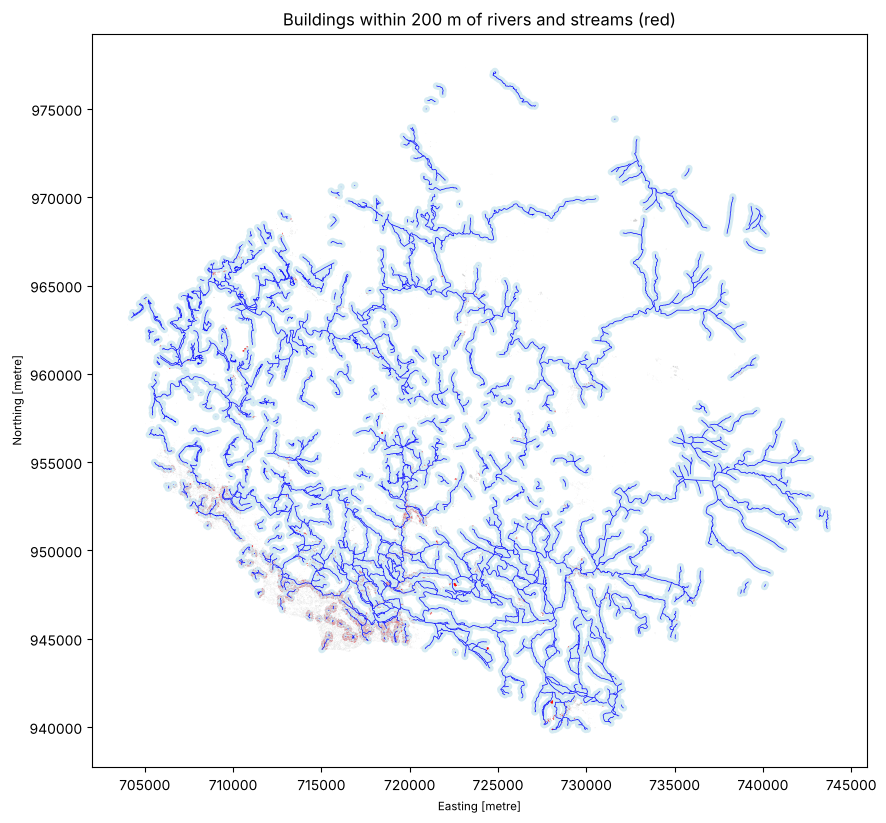

In [6]:
streams = w[w.fclass.isin(["river", "stream"])]
buf200 = gpd.GeoDataFrame(geometry=[streams.buffer(200).union_all()], crs=CRS)
near_b = gpd.sjoin(b, buf200, predicate="intersects", how="inner").drop(columns="index_right")

print("Total buildings:", len(b))
print("Within 200 m of river/stream:", len(near_b), f"({len(near_b)/len(b):.1%})")
named = near_b["name"].dropna()
print(f"Named buildings among them: {len(named)}\n\n10 names:")
for n in named.head(10): print("  -", n)

fig, ax = plt.subplots(figsize=(10, 10))
buf200.plot(ax=ax, color="lightblue", alpha=0.5)
b.plot(ax=ax, color="lightgrey")
near_b.plot(ax=ax, color="red")
streams.plot(ax=ax, color="blue", linewidth=0.5)
ax.set_title("Buildings within 200 m of rivers and streams (red)"); plt.show()

## Task 5 – Hospitals within 750 m of primary and trunk roads
The data has no `trunk` class, so `primary`, `primary_link` (and `trunk` / `trunk_link` if present) are used.

Road classes used: {'primary': 128, 'primary_link': 13}

Hospitals total: 57 | within 750 m of primary/trunk: 34

10 names:
  - RIMS
  - Government District Hospital
  - Karunya Hospital and Diabetic Centre
  - Santhigiri Ayurveda Hospital and Research Institute
  - Leela Ravi Medical Trust Hospital
  - priya dental clinic
  - health centre
  - SAF Hospital, Vattappara
  - Ayurveda Hospital Vamanapuram
  - Homeo Hospital Vamanapuram


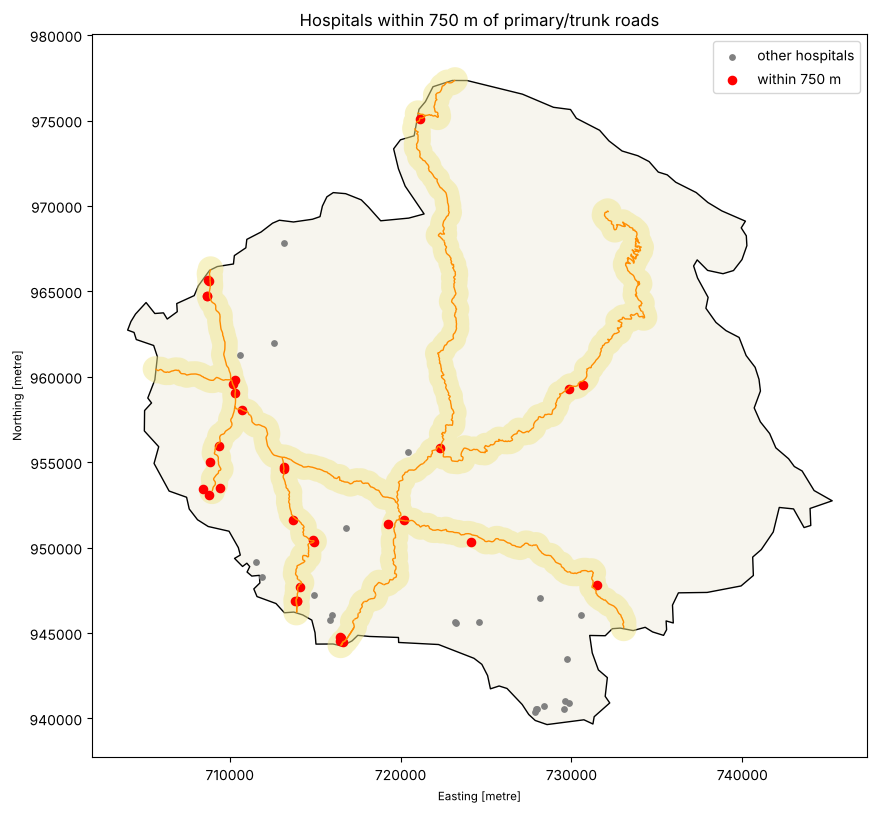

In [7]:
hosp = p[p.fclass == "hospital"]
main_roads = r[r.fclass.isin(["primary", "primary_link", "trunk", "trunk_link"])]
print("Road classes used:", main_roads.fclass.value_counts().to_dict())

buf750 = gpd.GeoDataFrame(geometry=[main_roads.buffer(750).union_all()], crs=CRS)
near_h = gpd.sjoin(hosp, buf750, predicate="within", how="inner").drop(columns="index_right")
print(f"\nHospitals total: {len(hosp)} | within 750 m of primary/trunk: {len(near_h)}")
print("\n10 names:")
for n in near_h["name"].dropna().head(10): print("  -", n)

fig, ax = plt.subplots(figsize=(10, 10))
boundary.plot(ax=ax, color="#f7f5ee", edgecolor="k")
buf750.plot(ax=ax, color="khaki", alpha=0.5)
main_roads.plot(ax=ax, color="darkorange", linewidth=1)
hosp.plot(ax=ax, color="grey", markersize=15, label="other hospitals")
near_h.plot(ax=ax, color="red", markersize=35, label="within 750 m")
ax.legend(); ax.set_title("Hospitals within 750 m of primary/trunk roads"); plt.show()

## Task 6 – Bridges on top of rivers
Bridge segments = roads with `bridge == 'T'`; a bridge is *on a river* if it crosses a river/canal line. (Counted per road segment, so one named bridge can be several segments.)

Total bridge segments in taluk: 606
Bridge segments on top of rivers/canals: 68
Distinct bridge/road names (25):
  - 101 Acre Road.
  - Aruvikkara Check Dam cum Bridge (DS)
  - Attingal - Nedumangad Road
  - Bonacaud Road
  - Check Dam cum Bridge at Kovil kadavu Aruvikkara(DS)
  - Enikkara road
  - Gosalakunnu Road.
  - Irumbupala Old Bridge
  - Irumbupalam New Bridge
  - Kallara-Muthuvila-Nedumagadu Road
  - LIC - Netta Bridge
  - MC Road
  - Meenmutty falls road
  - Mulamukku Road
  - Nedumangad - Shorlacode Road
  - Nedumangad Vattappara Road
  - Netta Bridge (Old Rajapatha Road)
  - Old Rajapatha
  - Ponnamchundu Bridge
  - Suryakanthi Bridge
  - Thiruvananthapuram - Ponmudi Road
  - Thiruvanathapuram - Thenmala Road
  - Uliyoor Road
  - Vamanapuram Aramthanam Road
  - koovakudi bridge
Unnamed bridge segments: 42


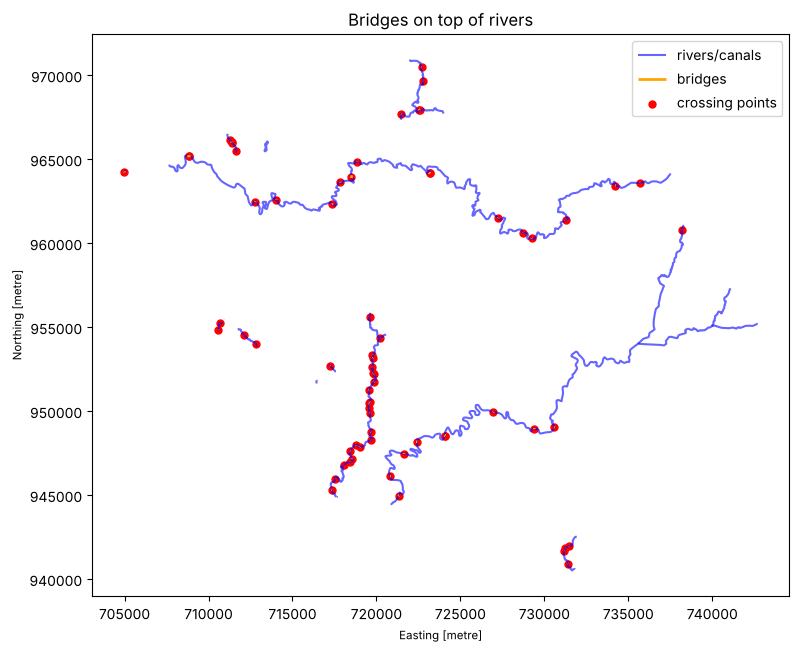

In [8]:
bridges = r[r.bridge == "T"]
rivers = w[w.fclass.isin(["river", "canal"])]          # note: the class is 'canal' (singular) in this data

on_river = gpd.sjoin(bridges, rivers[["geometry"]], predicate="intersects", how="inner")
on_river = on_river[~on_river.index.duplicated()]       # one row per bridge segment

print("Total bridge segments in taluk:", len(bridges))
print("Bridge segments on top of rivers/canals:", len(on_river))
names = sorted(on_river["name"].dropna().unique())
print(f"Distinct bridge/road names ({len(names)}):")
for n in names: print("  -", n)
print("Unnamed bridge segments:", on_river["name"].isna().sum())

cross = gpd.overlay(rivers[["geometry"]], on_river[["geometry"]], how="intersection", keep_geom_type=False)
fig, ax = plt.subplots(figsize=(9, 9))
rivers.plot(ax=ax, color="blue", linewidth=1.5, alpha=0.6, label="rivers/canals")
on_river.plot(ax=ax, color="orange", linewidth=2, label="bridges")
cross.plot(ax=ax, color="red", markersize=25, label="crossing points")
ax.legend(); ax.set_title("Bridges on top of rivers"); plt.show()

## Task 7 – Primary and tertiary roads inside forest

/usr/local/lib/python3.13/dist-packages/geopandas/tools/overlay.py:386: UserWarning: `keep_geom_type=True` in overlay resulted in 1 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  result = _collection_extract(result, geom_type, keep_geom_type_warning)


Road pieces inside forest: 6 | total length: 13.5 km

Names of primary/tertiary roads inside forest (km inside forest):
fclass    name                              
tertiary  Vithura - Bonacaud Road               7.18
primary   Thiruvananthapuram - Ponmudi Road     6.02
tertiary  MEENMOOD KUTTIMOOD PUTHANKADA ROAD    0.29
Unnamed pieces: 0


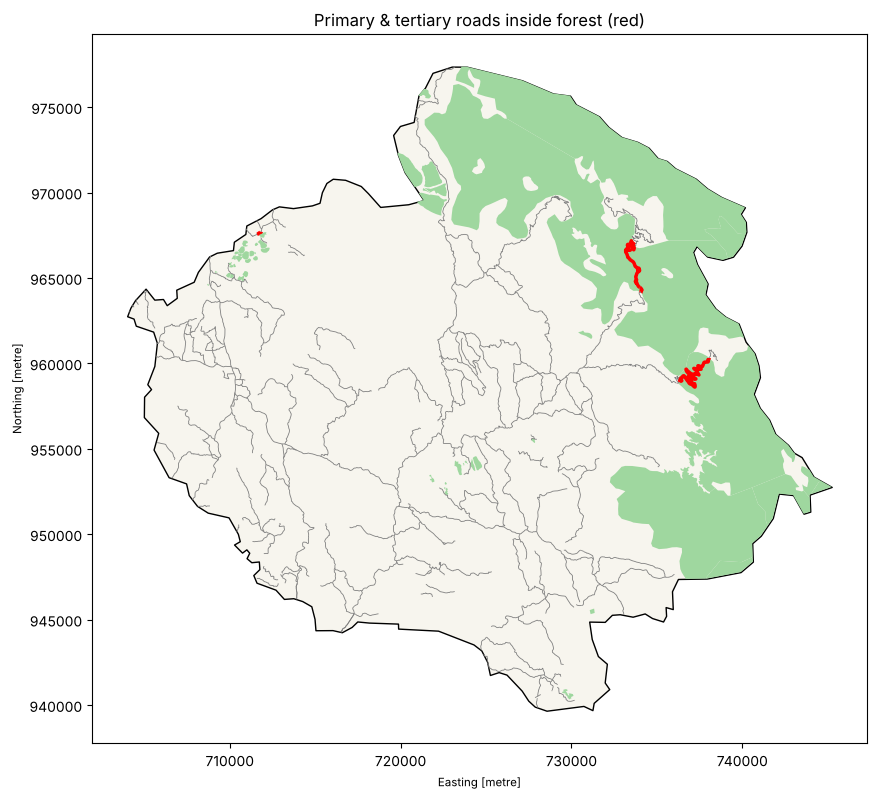

In [9]:
forest = l[l.fclass == "forest"]
pt = r[r.fclass.isin(["primary", "tertiary"])]
inside = gpd.overlay(pt, forest[["geometry"]], how="intersection")   # portions of the roads lying in forest
inside["len_m"] = inside.length

print("Road pieces inside forest:", len(inside), "| total length: %.1f km" % (inside.len_m.sum()/1000))
g = inside.groupby(["fclass", "name"], dropna=False).len_m.sum().div(1000).round(2).sort_values(ascending=False)
print("\nNames of primary/tertiary roads inside forest (km inside forest):")
print(g.to_string())
print("Unnamed pieces:", inside["name"].isna().sum())

fig, ax = plt.subplots(figsize=(10, 10))
boundary.plot(ax=ax, color="#f7f5ee", edgecolor="k")
forest.plot(ax=ax, color="#9fd79f")
pt.plot(ax=ax, color="grey", linewidth=0.6)
inside.plot(ax=ax, color="red", linewidth=2.5)
ax.set_title("Primary & tertiary roads inside forest (red)"); plt.show()